In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_squared_error

Matplotlib is building the font cache; this may take a moment.


In [3]:
df = pd.read_csv("uber.csv").dropna()
df = df.drop(columns=["key","Unnamed: 0"], errors='ignore')
df = df[df.fare_amount.between(1, 100)]

In [4]:
q1 , q3 = df.fare_amount.quantile([0.25, 0.75])
iqr = q3 - q1
df = df[df.fare_amount.between(q1 - 1.5*iqr, q3 + 1.5*iqr)]

                 distance  passenger_count  fare_amount
distance         1.000000        -0.000595     0.002764
passenger_count -0.000595         1.000000     0.012601
fare_amount      0.002764         0.012601     1.000000


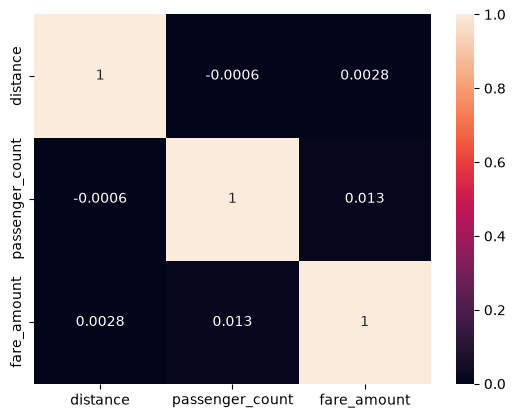

In [8]:
lat1, lat2 = np.radians(df.pickup_latitude), np.radians(df.dropoff_latitude)
lon1, lon2 = np.radians(df.pickup_longitude), np.radians(df.dropoff_longitude)
a = np.sin((lat2 - lat1)/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1)/2)**2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

features = ["distance", "passenger_count"]
print(df[features + ["fare_amount"]].corr())
sns.heatmap(df[features + ["fare_amount"]].corr(), annot=True)
sns.plt.show() if hasattr(sns, "plt") else None

In [9]:
X, y = df[features], df.fare_amount
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42) 

In [10]:
models = [LinearRegression(), RandomForestRegressor(n_estimators=100, random_state=42)]

In [11]:
for model in models:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(type(model).__name__)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

LinearRegression
R2 Score: 5.5017578626803676e-05
RMSE: 4.150037240311508
RandomForestRegressor
R2 Score: 0.5639685445301585
RMSE: 2.7404561125653997
